# Reconocimiento de entidades nombradas en español con BETO y CoNLL-2002

Este notebook resuelve la tarea completa: exploración del corpus, tokenización y alineación de etiquetas, entrenamiento de dos modelos de clasificación por token sobre `dccuchile/bert-base-spanish-wwm-cased` (BETO) y evaluación final con `seqeval`.

| Sección | Contenido | Puntos |
|---|---|---|
| 0 | Configuración, semillas y dispositivo | — |
| 1 | Preparación y exploración del corpus | 10 |
| 2 | Tokenización y alineación de etiquetas | 20 |
| 3 | Modelo A (encoder congelado) y Modelo B (*fine-tuning* completo) | 40 |
| 4 | Evaluación final y comparación | 30 |

**Protocolo experimental.** `esp.train` se usa para ajustar pesos; `esp.testa` para toda decisión (longitud máxima, hiperparámetros, época y configuración); `esp.testb` se evalúa una sola vez, al final, con los dos modelos ya seleccionados. La función `evaluate_on_test_once` persiste el resultado y se niega a recalcularlo.

**Modo de prueba rápida.** Con `NER_SMOKE=1` el notebook recorre todas las celdas con un subconjunto mínimo, escribe en `outputs_smoke/` y sustituye la prueba por validación, de modo que el pipeline completo se depura sin tocar `esp.testb`.

## 0. Configuración

In [1]:
import os

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import gc
import hashlib
import json
import logging
import platform
import random
import time
import warnings
from collections import Counter
from dataclasses import asdict, dataclass
from importlib.metadata import version
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from seqeval.metrics import classification_report
from seqeval.scheme import IOB2, Entities
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup,
)

huggingface_hub.logging.set_verbosity_error()
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", None, "display.width", 160)

SEED = 42
MODEL_NAME = "dccuchile/bert-base-spanish-wwm-cased"
SPLIT_FILES = {"train": "esp.train", "validación": "esp.testa", "prueba": "esp.testb"}
ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]
LABELS = ["O"] + [f"{prefix}-{etype}" for etype in ENTITY_TYPES for prefix in "BI"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}
IGNORE_INDEX = -100
EVAL_BATCH_SIZE = 32

SMOKE = os.environ.get("NER_SMOKE") == "1"
FORCE_RETRAIN = False  # True ignora las corridas guardadas en outputs/runs
OUT_DIR = Path("outputs_smoke" if SMOKE else "outputs")
FIG_DIR = OUT_DIR / "figures" if SMOKE else Path("figures")
RUNS_DIR = OUT_DIR / "runs"
for directory in (FIG_DIR, RUNS_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def set_seed(seed: int = SEED) -> None:
    """Fija las semillas de Python, NumPy y PyTorch (incluye CUDA y MPS)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def pick_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def sync_device() -> None:
    """Espera a que termine el trabajo pendiente para que los cronómetros sean reales."""
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


def free_memory() -> None:
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def log(message: str) -> None:
    """Imprime en el notebook y deja traza en disco durante entrenamientos largos."""
    print(message, flush=True)
    with (OUT_DIR / "train.log").open("a", encoding="utf-8") as handle:
        handle.write(f"{time.strftime('%H:%M:%S')} {message}\n")


DEVICE = pick_device()
set_seed()

environment = {
    "python": platform.python_version(),
    "plataforma": platform.platform(),
    "dispositivo": DEVICE.type,
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "seqeval": version("seqeval"),
    "scikit-learn": version("scikit-learn"),
    "modo": "smoke" if SMOKE else "completo",
}
pd.Series(environment, name="valor").to_frame()

,valor
python,3.12.14
plataforma,macOS-26.6.2-arm64-arm-64bit
dispositivo,mps
torch,2.15.0
transformers,5.22.1
seqeval,1.2.2
scikit-learn,1.9.1
modo,completo


In [2]:
# Estilo común de las figuras: paleta categórica validada (orden fijo), trazos finos y rejilla discreta.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLORS = {"A": SERIES[0], "B": SERIES[1]}
SPLIT_COLORS = dict(zip(SPLIT_FILES, SERIES))

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT, "text.color": INK,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False,
})


def save_figure(fig, name: str) -> None:
    """Guarda la figura en PDF (reporte) y PNG, y la deja visible en el notebook."""
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Preparación y exploración del corpus

### 1.1 Lectura y validación

Cada línea contiene `palabra POS etiqueta` y una línea en blanco separa oraciones. La columna POS no se usa. El lector aborta ante cualquier línea mal formada en lugar de descartarla, porque un descarte silencioso desalinearía palabras y etiquetas.

La auditoría del corpus muestra que las tres particiones contienen exactamente una oración que comienza con `I-X`: son oraciones cortadas en mitad de una entidad. En esquema IOB2 esa secuencia es inválida, y `seqeval` en modo estricto ignoraría esa entidad de referencia sin avisar. Por ello `repair_iob2` convierte un `I-X` que no continúa una entidad en `B-X`, la misma lectura que hace el script oficial `conlleval`. La regla es determinista, se aplica por igual a las tres particiones y no depende de ninguna predicción.

In [3]:
@dataclass
class Split:
    """Una partición: oraciones como listas paralelas de palabras y etiquetas."""
    name: str
    tokens: list
    tags: list
    n_repaired: int = 0


def locate_data() -> Path:
    """Devuelve la carpeta local del corpus; aborta si falta algún archivo."""
    local = Path(".")
    missing = [name for name in SPLIT_FILES.values() if not (local / name).is_file()]
    if missing:
        raise FileNotFoundError(f"faltan archivos del corpus: {missing}")
    return local


def read_conll(path: Path, name: str) -> Split:
    """Reconstruye oraciones y etiquetas; aborta si una línea no tiene tres columnas."""
    tokens, tags, current_tokens, current_tags = [], [], [], []
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, 1):
            if not line.strip():
                if current_tokens:
                    tokens.append(current_tokens)
                    tags.append(current_tags)
                    current_tokens, current_tags = [], []
                continue
            fields = line.split()
            if len(fields) != 3:
                raise ValueError(f"{path}:{line_number}: se esperaban 3 columnas, hay {len(fields)}")
            current_tokens.append(fields[0])
            current_tags.append(fields[2])
    if current_tokens:
        tokens.append(current_tokens)
        tags.append(current_tags)
    return Split(name, tokens, tags)


def repair_iob2(tags: list) -> tuple:
    """Convierte en B-X todo I-X que no continúe una entidad del mismo tipo."""
    fixed, previous, repairs = [], "O", 0
    for tag in tags:
        if tag.startswith("I-") and previous[2:] != tag[2:]:
            tag = "B-" + tag[2:]
            repairs += 1
        fixed.append(tag)
        previous = tag
    return fixed, repairs


def extract_entities(tags: list) -> list:
    """Devuelve (tipo, inicio, fin) con la semántica estricta de IOB2; fin es exclusivo."""
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ["O"]):
        prefix, _, tag_kind = tag.partition("-")
        if start is not None and not (prefix == "I" and tag_kind == kind):
            spans.append((kind, start, i))
            start = None
        if prefix == "B":
            start, kind = i, tag_kind
    return spans


def validate_split(split: Split, path: Path) -> None:
    """Comprueba correspondencia palabra-etiqueta, vocabulario, BIO y conteo independiente."""
    raw_lines = [line for line in path.read_text(encoding="utf-8").split("\n") if line.strip()]
    assert len(split.tokens) == len(split.tags), "número distinto de oraciones y de secuencias de etiquetas"
    assert all(len(w) == len(t) and len(w) > 0 for w, t in zip(split.tokens, split.tags)), "longitudes distintas"
    assert sum(map(len, split.tokens)) == len(raw_lines), "se perdieron palabras al leer"
    assert {tag for tags in split.tags for tag in tags} <= set(LABELS), "etiqueta desconocida"
    assert sum(repair_iob2(tags)[1] for tags in split.tags) == 0, "BIO inválido tras la reparación"
    assert all(
        extract_entities(tags) == [(e.tag, e.start, e.end) for e in Entities([tags], IOB2).entities[0]]
        for tags in split.tags
    ), "extract_entities no coincide con seqeval"


DATA_DIR = locate_data()
splits = {}
for name, filename in SPLIT_FILES.items():
    split = read_conll(DATA_DIR / filename, name)
    repaired = [repair_iob2(tags) for tags in split.tags]
    split.tags = [tags for tags, _ in repaired]
    split.n_repaired = sum(count for _, count in repaired)
    validate_split(split, DATA_DIR / filename)
    splits[name] = split

corpus_summary = pd.DataFrame({
    name: {
        "Oraciones": len(s.tokens),
        "Palabras": sum(map(len, s.tokens)),
        "Entidades completas": sum(len(extract_entities(t)) for t in s.tags),
        "I-X reparados": s.n_repaired,
    } for name, s in splits.items()
}).T
corpus_summary["Longitud media"] = (corpus_summary["Palabras"] / corpus_summary["Oraciones"]).round(1)
display(corpus_summary)
print("Validación superada: palabras y etiquetas coinciden en las tres particiones.")

,Oraciones,Palabras,Entidades completas,I-X reparados,Longitud media
train,8323,264715,18798,1,31.8
validación,1915,52923,4352,1,27.6
prueba,1517,51533,3559,1,34.0


Validación superada: palabras y etiquetas coinciden en las tres particiones.


In [4]:
# Fuga de información: oraciones idénticas entre particiones (se informan; la partición oficial no se altera).
sentence_sets = {name: {" ".join(words) for words in s.tokens} for name, s in splits.items()}
overlap = pd.DataFrame([
    {"Par": f"{a} ∩ {b}", "Oraciones únicas compartidas": len(sentence_sets[a] & sentence_sets[b]),
     "Ejemplos": ", ".join(sorted(sentence_sets[a] & sentence_sets[b], key=len)[:4])}
    for a, b in [("train", "validación"), ("train", "prueba"), ("validación", "prueba")]
])
overlap

,Par,Oraciones únicas compartidas,Ejemplos
0,train ∩ validación,185,"-, Mérida ., ( PP ) ., Badajoz ."
1,train ∩ prueba,111,"-, EFE ., ( EFE ) ., Individual ."
2,validación ∩ prueba,21,"-, ( EFE ) ., Panamá , 23 may ( EFE ) ., Madrid , 23 may ( EFE ) ."


Las coincidencias entre particiones son fragmentos de teletipo (firmas de agencia, guiones y titulares repetidos), no oraciones informativas. Se conserva la partición oficial para que los resultados sean comparables con la literatura.

### 1.2 Exploración

In [5]:
tag_counts = pd.DataFrame({name: Counter(t for tags in s.tags for t in tags) for name, s in splits.items()}).loc[LABELS]
tag_share = (100 * tag_counts / tag_counts.sum()).round(2).add_suffix(" %")
display(pd.concat([tag_counts, tag_share], axis=1))

entity_rows = {}
for name, s in splits.items():
    spans = [span for tags in s.tags for span in extract_entities(tags)]
    counts = Counter(kind for kind, _, _ in spans)
    entity_rows[name] = {kind: counts[kind] for kind in ENTITY_TYPES}
entity_counts = pd.DataFrame(entity_rows).T
entity_counts["Total"] = entity_counts.sum(axis=1)
entity_share = (100 * entity_counts[ENTITY_TYPES].div(entity_counts["Total"], axis=0)).round(1)
display(entity_counts, entity_share.add_suffix(" %"))

entity_lengths = pd.Series({
    kind: np.mean([end - start for s in splits.values() for tags in s.tags
                   for k, start, end in extract_entities(tags) if k == kind])
    for kind in ENTITY_TYPES
}, name="Palabras por entidad (media)").round(2)
display(entity_lengths.to_frame().T)

length_stats = pd.DataFrame({
    name: pd.Series([len(w) for w in s.tokens]).describe(percentiles=[0.5, 0.95, 0.99]).round(1)
    for name, s in splits.items()
}).T
length_stats

,train,validación,prueba,train %,validación %,prueba %
O,231920,45356,45355,87.61,85.70,88.01
B-PER,4321,1222,735,1.63,2.31,1.43
I-PER,3903,859,634,1.47,1.62,1.23
B-ORG,7390,1700,1400,2.79,3.21,2.72
I-ORG,4992,1366,1104,1.89,2.58,2.14
B-LOC,4914,985,1084,1.86,1.86,2.10
I-LOC,1890,336,325,0.71,0.63,0.63
B-MISC,2173,445,340,0.82,0.84,0.66
I-MISC,3212,654,556,1.21,1.24,1.08


,PER,ORG,LOC,MISC,Total
train,4321,7390,4914,2173,18798
validación,1222,1700,985,445,4352
prueba,735,1400,1084,340,3559


,PER %,ORG %,LOC %,MISC %
train,23.0,39.3,26.1,11.6
validación,28.1,39.1,22.6,10.2
prueba,20.7,39.3,30.5,9.6


,PER,ORG,LOC,MISC
Palabras por entidad (media),1.86,1.71,1.37,2.49


,count,mean,std,min,50%,95%,99%,max
train,8323.0,31.8,25.1,1.0,34.0,62.0,76.0,1238.0
validación,1915.0,27.6,20.1,1.0,28.0,59.0,77.0,141.0
prueba,1517.0,34.0,20.3,1.0,37.0,63.0,74.0,202.0


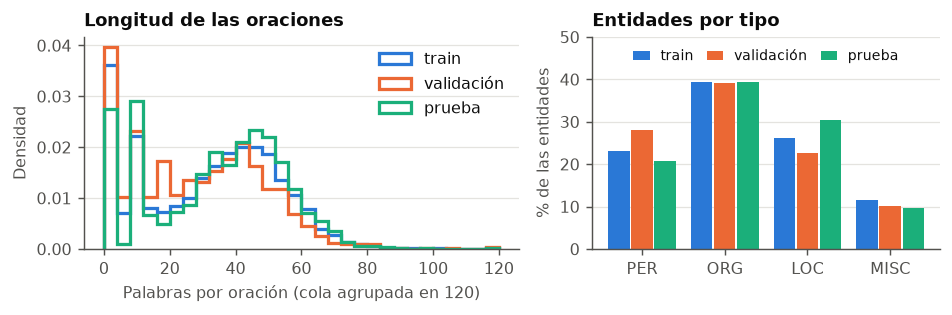

In [6]:
fig, (ax_length, ax_share) = plt.subplots(1, 2, figsize=(7.4, 2.5), gridspec_kw={"width_ratios": [1.25, 1]})

bins = np.arange(0, 124, 4)
for name, s in splits.items():
    lengths = np.clip([len(w) for w in s.tokens], 0, 120)
    ax_length.hist(lengths, bins=bins, density=True, histtype="step", linewidth=1.8,
                   color=SPLIT_COLORS[name], label=name)
ax_length.set(title="Longitud de las oraciones", xlabel="Palabras por oración (cola agrupada en 120)", ylabel="Densidad")
ax_length.legend()
ax_length.grid(axis="x", visible=False)

width = 0.26
positions = np.arange(len(ENTITY_TYPES))
for offset, name in zip((-1, 0, 1), splits):
    ax_share.bar(positions + offset * (width + 0.02), entity_share.loc[name, ENTITY_TYPES], width,
                 color=SPLIT_COLORS[name], label=name)
ax_share.set_xticks(positions, ENTITY_TYPES)
ax_share.set(title="Entidades por tipo", ylabel="% de las entidades", ylim=(0, 50))
ax_share.grid(axis="x", visible=False)
ax_share.legend(loc="upper center", ncols=3, fontsize=7.5, columnspacing=1, handlelength=1.2)
fig.tight_layout()
save_figure(fig, "corpus")

In [7]:
def annotate(words: list, tags: list) -> str:
    """Oración legible con cada entidad entre corchetes y su tipo."""
    spans = {start: (end, kind) for kind, start, end in extract_entities(tags)}
    parts, i = [], 0
    while i < len(words):
        if i in spans:
            end, kind = spans[i]
            parts.append(f"[{' '.join(words[i:end])}]{kind}")
            i = end
        else:
            parts.append(words[i])
            i += 1
    return " ".join(parts)


def annotated_example(split: Split, kind: str) -> dict:
    """Primera oración de 10 a 22 palabras cuyas entidades son todas del tipo pedido."""
    for words, tags in zip(split.tokens, split.tags):
        kinds = {k for k, _, _ in extract_entities(tags)}
        if kinds == {kind} and 10 <= len(words) <= 22:
            return {"Tipo": kind, "Oración anotada": annotate(words, tags),
                    "Etiquetas": " ".join(tags)}
    raise LookupError(f"sin ejemplo para {kind}")


pd.DataFrame([annotated_example(splits["train"], kind) for kind in ENTITY_TYPES])

,Tipo,Oración anotada,Etiquetas
0,PER,"El alcalde , [José Luis Díez]PER , hablará sobre diversas cuestiones de interés municipal .",O O O B-PER I-PER I-PER O O O O O O O O O
1,ORG,"Como contrapartida , [Deutsche Telekom]ORG venderá al consorcio francés su participación del 25 por ciento en el empresa mixta británica [MetroHoldings]ORG .",O O O B-ORG I-ORG O O O O O O O O O O O O O O O B-ORG O
2,LOC,10:00 h. - [Jaraíz de la Vera]LOC ( [Cáceres]LOC ) .,O O O B-LOC I-LOC I-LOC I-LOC O B-LOC O O
3,MISC,"Comenzará el Congreso "" [Carlos. y el fin de una época. 1500-1558]MISC "" .",O O O O B-MISC I-MISC I-MISC I-MISC I-MISC I-MISC I-MISC I-MISC O O


**Lectura del análisis exploratorio.**

- La clase `O` representa cerca del 87 % de las palabras. Por tanto, la exactitud por token es una métrica poco informativa: un clasificador que siempre respondiera `O` ya superaría el 85 %. La métrica que interesa es F1 de entidades completas.
- `ORG` es el tipo más frecuente y `MISC` el más escaso. Además, `MISC` tiene las entidades más largas y es una categoría residual heterogénea, de modo que es previsible que sea la más difícil.
- La mediana es de unas 30 palabras por oración, pero la cola es muy larga: `esp.train` contiene una "oración" de 1238 palabras, en realidad un bloque de texto sin segmentar. Esto obliga a estudiar la longitud en subtokens antes de fijar el truncamiento.
- La prueba difiere algo de validación: tiene más `LOC` y menos `PER`. Esto anticipa que el F1 de validación y el de prueba no tienen por qué coincidir.

## 2. Tokenización y alineación de etiquetas

### 2.1 Tokenizer oficial y longitud máxima

`word_ids()` solo existe en los tokenizers rápidos, y BETO es un modelo *cased*: se verifica que el tokenizer conserve mayúsculas y acentos, que son señales fuertes para NER en español.

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
assert tokenizer.is_fast, "word_ids() requiere un tokenizer rápido"
assert tokenizer.tokenize("Bogotá") == ["Bogotá"], "el tokenizer altera mayúsculas o acentos"
print("Clase:", type(tokenizer).__name__, "| vocabulario:", len(tokenizer), "| longitud máxima del modelo:", tokenizer.model_max_length)
print("Normalizador:", tokenizer.backend_tokenizer.normalizer)
print("Ejemplo:", tokenizer.tokenize("La Generalitat de Catalunya y Ñandú"))


def truncation_table(split: Split, candidates: list) -> pd.DataFrame:
    """Coste de cada longitud máxima: oraciones, palabras y entidades que dejarían de verse."""
    encoded = tokenizer(split.tokens, is_split_into_words=True, add_special_tokens=True)
    lengths = np.array([len(ids) for ids in encoded["input_ids"]])
    rows = []
    for limit in candidates:
        lost_words = affected_entities = 0
        for i in np.flatnonzero(lengths > limit):
            kept = max(w for w in encoded.word_ids(i)[:limit - 1] if w is not None) + 1
            lost_words += len(split.tokens[i]) - kept
            affected_entities += sum(end > kept for _, _, end in extract_entities(split.tags[i]))
        rows.append({
            "Partición": split.name, "max_length": limit,
            "Oraciones truncadas": int((lengths > limit).sum()),
            "% oraciones": round(100 * float((lengths > limit).mean()), 3),
            "Palabras perdidas": lost_words, "Entidades afectadas": affected_entities,
        })
    return pd.DataFrame(rows)


CANDIDATE_LENGTHS = [64, 96, 128, 192, 256, 384, 512]
train_lengths = np.array([len(ids) for ids in tokenizer(splits["train"].tokens, is_split_into_words=True)["input_ids"]])
print("Subtokens por oración en train:", {
    "media": round(float(train_lengths.mean()), 1),
    **{f"p{q}": round(float(np.percentile(train_lengths, q)), 1) for q in (50, 95, 99, 99.9)},
    "máximo": int(train_lengths.max()),
})
truncation = pd.concat([truncation_table(splits[name], CANDIDATE_LENGTHS) for name in ("train", "validación")])
display(truncation)

val_truncation = truncation[truncation["Partición"] == "validación"]
MAX_LENGTH = int(val_truncation.loc[val_truncation["Entidades afectadas"] == 0, "max_length"].min())
assert MAX_LENGTH <= tokenizer.model_max_length
print(f"MAX_LENGTH = {MAX_LENGTH}")

Clase: BertTokenizer | vocabulario: 31002 | longitud máxima del modelo: 512
Normalizador: BertNormalizer(clean_text=True, handle_chinese_chars=True, strip_accents=False, lowercase=False)
Ejemplo: ['La', 'Generalitat', 'de', 'Catalunya', 'y', 'Ñ', '##and', '##ú']


Subtokens por oración en train: {'media': 39.8, 'p50': 42.0, 'p95': 74.0, 'p99': 92.0, 'p99.9': 216.2, 'máximo': 3920}


,Partición,max_length,Oraciones truncadas,% oraciones,Palabras perdidas,Entidades afectadas
0,train,64,1147,13.781,12748,1198
1,train,96,68,0.817,3168,459
2,train,128,27,0.324,2342,353
3,train,192,10,0.120,1744,247
4,train,256,6,0.072,1531,207
5,train,384,2,0.024,1300,169
6,train,512,2,0.024,1217,158
0,validación,64,191,9.974,2150,273
1,validación,96,18,0.940,431,103
2,validación,128,6,0.313,243,62


MAX_LENGTH = 384


**Justificación de `MAX_LENGTH`.** La decisión usa solo entrenamiento y validación. BERT admite como máximo 512 posiciones, de modo que el bloque de 3920 subtokens de `esp.train` debe truncarse en cualquier caso. Los valores habituales son engañosos en este corpus: con 128 subtokens se cubre el 99.7 % de las oraciones, pero las pocas truncadas son densas en entidades y validación perdería decenas de ellas.

La regla es elegir el menor candidato que no afecte a ninguna entidad de validación. Su coste es muy bajo porque el *padding* es dinámico: cada lote se rellena hasta su oración más larga, no hasta `MAX_LENGTH`, así que solo las pocas oraciones largas consumen más cómputo. Ni la longitud ni el truncamiento se decidieron mirando la prueba.

**Evaluación honesta ante truncamiento.** Las métricas se calculan siempre frente a las etiquetas originales completas. Si una palabra quedara truncada, se le asigna `O`, de modo que una entidad perdida cuenta como falso negativo en lugar de desaparecer del denominador.

### 2.2 Alineación con `word_ids()`

In [9]:
def align_labels(word_ids: list, word_tags: list) -> list:
    """Etiqueta el primer subtoken de cada palabra y marca el resto con IGNORE_INDEX.

    `word_ids` trae None en los tokens especiales y repite el índice de palabra en los
    subtokens posteriores. El padding se añade después, en el colador, también con -100.
    """
    aligned, previous = [], None
    for word_id in word_ids:
        if word_id is None or word_id == previous:
            aligned.append(IGNORE_INDEX)
        else:
            aligned.append(LABEL2ID[word_tags[word_id]])
        previous = word_id
    return aligned


def encode_split(split: Split, max_length: int) -> list:
    """Tokeniza una partición y devuelve un ejemplo alineado por oración, sin padding."""
    encoded = tokenizer(split.tokens, is_split_into_words=True, truncation=True, max_length=max_length)
    return [
        {
            "input_ids": encoded["input_ids"][i],
            "attention_mask": encoded["attention_mask"][i],
            "token_type_ids": encoded["token_type_ids"][i],
            "labels": align_labels(encoded.word_ids(i), split.tags[i]),
            "word_ids": encoded.word_ids(i),
        }
        for i in range(len(split.tokens))
    ]


def data_fingerprint(encoded: list) -> str:
    """Huella de los datos tokenizados: prueba que ambos modelos usan exactamente los mismos."""
    digest = hashlib.sha256()
    for example in encoded:
        digest.update(np.asarray(example["input_ids"] + example["labels"], dtype=np.int32).tobytes())
    return digest.hexdigest()[:16]


class NerDataset(Dataset):
    """Expone solo los campos que consume el modelo; word_ids queda fuera del lote."""
    FIELDS = ("input_ids", "attention_mask", "token_type_ids", "labels")

    def __init__(self, encoded: list):
        self.encoded = encoded

    def __len__(self) -> int:
        return len(self.encoded)

    def __getitem__(self, index: int) -> dict:
        return {field: self.encoded[index][field] for field in self.FIELDS}


collator = DataCollatorForTokenClassification(tokenizer, label_pad_token_id=IGNORE_INDEX, return_tensors="pt")


def make_loader(encoded: list, batch_size: int, shuffle: bool = False, seed: int = SEED) -> DataLoader:
    """DataLoader con padding dinámico; el barajado depende solo de la semilla."""
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(NerDataset(encoded), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collator, generator=generator)


encoded_splits = {name: encode_split(split, MAX_LENGTH) for name, split in splits.items()}
fingerprints = {name: data_fingerprint(encoded) for name, encoded in encoded_splits.items()}
fingerprints

{'train': 'a490aa20e11b820e',
 'validación': 'cb02de97967ae4f9',
 'prueba': '68cef21de77c87c0'}

### 2.3 Verificación automática de la alineación

`check_alignment` recorre **todas** las oraciones y falla ante cualquier inconsistencia. Se ejecuta con `MAX_LENGTH` y también con un límite artificial de 32 subtokens, para forzar truncamiento masivo. Las demás pruebas cubren el ejemplo del enunciado, el *padding* del colador y un viaje de ida y vuelta: si las "predicciones" son las propias etiquetas alineadas, el F1 debe ser exactamente 1 salvo por las entidades cortadas por el truncamiento.

In [10]:
def labels_to_tags(labels: list, n_words: int) -> list:
    """Pasa de ids alineados a etiquetas por palabra; las palabras truncadas valen O."""
    tags = [ID2LABEL[label] for label in labels if label != IGNORE_INDEX]
    return tags + ["O"] * (n_words - len(tags))


def check_alignment(split: Split, encoded: list, max_length: int) -> dict:
    """Valida cada oración tokenizada y devuelve un resumen del truncamiento."""
    cls_id, sep_id = tokenizer.cls_token_id, tokenizer.sep_token_id
    n_truncated = lost_words = 0
    for words, tags, example in zip(split.tokens, split.tags, encoded):
        ids, labels, word_ids = example["input_ids"], example["labels"], example["word_ids"]
        assert len(ids) == len(labels) == len(word_ids) == sum(example["attention_mask"]) <= max_length
        assert ids[0] == cls_id and ids[-1] == sep_id
        assert word_ids[0] is None and word_ids[-1] is None and labels[0] == labels[-1] == IGNORE_INDEX
        first_positions = [i for i, w in enumerate(word_ids) if w is not None and (i == 0 or word_ids[i - 1] != w)]
        seen_words = [word_ids[i] for i in first_positions]
        assert seen_words == list(range(len(seen_words))), "palabras saltadas o desordenadas"
        assert [labels[i] for i in first_positions] == [LABEL2ID[tags[w]] for w in seen_words], "etiqueta incorrecta"
        assert sum(label != IGNORE_INDEX for label in labels) == len(seen_words), "subtokens posteriores etiquetados"
        if len(seen_words) < len(words):
            assert len(ids) == max_length, "faltan palabras sin que haya truncamiento"
            n_truncated += 1
            lost_words += len(words) - len(seen_words)
    return {"Partición": split.name, "max_length": max_length, "Oraciones": len(split.tokens),
            "Truncadas": n_truncated, "Palabras truncadas": lost_words}


def round_trip(split: Split, encoded: list) -> dict:
    """Las etiquetas alineadas, reconstruidas por palabra, deben reproducir el gold no truncado."""
    expected_hits = found = gold_total = 0
    for tags, example in zip(split.tags, encoded):
        kept = sum(label != IGNORE_INDEX for label in example["labels"])
        rebuilt = labels_to_tags(example["labels"], len(tags))
        gold = set(extract_entities(tags))
        found += len(gold & set(extract_entities(rebuilt)))
        expected_hits += sum(end <= kept for _, _, end in gold)
        gold_total += len(gold)
    assert found == expected_hits, "la reconstrucción no coincide con el gold"
    return {"Partición": split.name, "Entidades gold": gold_total, "Recuperadas": found}


# Ejemplo del enunciado, completo y cortado a 6 subtokens: [CLS] + 4 palabras + [SEP].
demo = Split("demo", [["Pedro", "trabaja", "en", "Banco", "de", "Bogota", "."]],
             [["B-PER", "O", "O", "B-ORG", "I-ORG", "I-ORG", "O"]])
assert labels_to_tags(encode_split(demo, 32)[0]["labels"], 7) == demo.tags[0]
assert labels_to_tags(encode_split(demo, 6)[0]["labels"], 7) == ["B-PER", "O", "O", "B-ORG", "O", "O", "O"]

# Padding: en un lote real, toda posición sin atención debe valer -100 y los lotes no superan MAX_LENGTH.
batch = next(iter(make_loader(encoded_splits["train"], batch_size=64)))
assert batch["input_ids"].shape == batch["labels"].shape
assert (batch["labels"][batch["attention_mask"] == 0] == IGNORE_INDEX).all()
assert (batch["input_ids"][batch["attention_mask"] == 0] == tokenizer.pad_token_id).all()
assert batch["input_ids"].shape[1] <= MAX_LENGTH

alignment_reports = [check_alignment(s, encoded_splits[n], MAX_LENGTH) for n, s in splits.items()]
truncated_32 = {n: encode_split(s, 32) for n, s in splits.items()}
alignment_reports += [check_alignment(s, truncated_32[n], 32) for n, s in splits.items()]
display(pd.DataFrame(alignment_reports))
display(pd.DataFrame([round_trip(s, encoded_splits[n]) for n, s in splits.items()]
                     + [round_trip(s, truncated_32[n]) for n, s in splits.items()]))
print("Alineación verificada con MAX_LENGTH y con truncamiento forzado a 32 subtokens.")

,Partición,max_length,Oraciones,Truncadas,Palabras truncadas
0,train,384,8323,2,1300
1,validación,384,1915,0,0
2,prueba,384,1517,0,0
3,train,32,8323,5207,103006
4,validación,32,1915,1062,18376
5,prueba,32,1517,1028,20370


,Partición,Entidades gold,Recuperadas
0,train,18798,18629
1,validación,4352,4352
2,prueba,3559,3559
3,train,18798,12391
4,validación,4352,2901
5,prueba,3559,2409


Alineación verificada con MAX_LENGTH y con truncamiento forzado a 32 subtokens.


La verificación sobre las tres particiones confirma que el corte ocurre donde debe. Con `MAX_LENGTH` solo se truncan dos oraciones de `train`; validación y prueba quedan completas, y por eso la exactitud por token "sin posiciones ignoradas" coincide con la exactitud sobre todas las palabras.

### 2.4 Análisis de la tokenización

In [11]:
def subtoken_row(words: list, tags: list, example: dict, word_index: int) -> dict:
    """Fila de la tabla: palabra, subtokens y etiqueta alineada de cada subtoken."""
    positions = [i for i, w in enumerate(example["word_ids"]) if w == word_index]
    subtokens = tokenizer.convert_ids_to_tokens([example["input_ids"][i] for i in positions])
    aligned = [ID2LABEL.get(example["labels"][i], "-100") for i in positions]
    return {"Palabra": words[word_index], "Etiqueta original": tags[word_index],
            "Subtokens": " | ".join(subtokens), "Etiquetas alineadas": " | ".join(aligned)}


def subtoken_examples(min_subtokens: int = 3) -> pd.DataFrame:
    """Una palabra multi-subtoken por cada etiqueta, tomada de entrenamiento."""
    rows = {}
    for words, tags, example in zip(splits["train"].tokens, splits["train"].tags, encoded_splits["train"]):
        pieces = Counter(w for w in example["word_ids"] if w is not None)
        for word_index, count in pieces.items():
            if count >= min_subtokens and tags[word_index] not in rows:
                rows[tags[word_index]] = subtoken_row(words, tags, example, word_index)
        if len(rows) == len(LABELS):
            break
    return pd.DataFrame([rows[label] for label in LABELS if label in rows])


subtoken_table = subtoken_examples()
assert len(subtoken_table) >= 5
display(subtoken_table)

# Vista completa de una oración: tokens especiales, subtokens posteriores y etiquetas alineadas.
example = encoded_splits["train"][2]
pd.DataFrame({
    "Subtoken": tokenizer.convert_ids_to_tokens(example["input_ids"]),
    "word_id": example["word_ids"],
    "label_id": example["labels"],
    "Etiqueta": [ID2LABEL.get(label, "ignorado") for label in example["labels"]],
}).head(14)

,Palabra,Etiqueta original,Subtokens,Etiquetas alineadas
0,imposibilita,O,imposi | ##bili | ##ta,O | -100 | -100
1,ZABALA,B-PER,Z | ##A | ##BA | ##LA,B-PER | -100 | -100 | -100
2,Ibarra,I-PER,Iba | ##r | ##ra,I-PER | -100 | -100
3,Commonwealth,B-ORG,Common | ##w | ##eal | ##th,B-ORG | -100 | -100 | -100
4,Telekom,I-ORG,Tele | ##k | ##om,I-ORG | -100 | -100
5,Cazoña,B-LOC,Ca | ##zo | ##ña,B-LOC | -100 | -100
6,Bidasoa,I-LOC,Bi | ##das | ##oa,I-LOC | -100 | -100
7,CrimeNet,B-MISC,Cri | ##me | ##N | ##et,B-MISC | -100 | -100 | -100
8,1500-1558,I-MISC,1500 | - | 155 | ##8,I-MISC | -100 | -100 | -100


,Subtoken,word_id,label_id,Etiqueta
0,[CLS],NaN,-100,ignorado
1,El,0.0,0,O
2,Abogado,1.0,1,B-PER
3,General,2.0,2,I-PER
4,del,3.0,2,I-PER
5,Estado,4.0,2,I-PER
6,",",5.0,0,O
7,Dar,6.0,1,B-PER
8,##yl,6.0,-100,ignorado
9,W,7.0,2,I-PER


In [12]:
def tokenization_stats(split: Split, encoded: list) -> dict:
    """Fragmentación de palabras y presencia de [UNK] en una partición."""
    pieces, unknown = [], Counter()
    for words, example in zip(split.tokens, encoded):
        pieces += Counter(w for w in example["word_ids"] if w is not None).values()
        for word_id, token_id in zip(example["word_ids"], example["input_ids"]):
            if token_id == tokenizer.unk_token_id:
                unknown[words[word_id]] += 1
    counts = np.array(pieces)
    return {"Partición": split.name, "Subtokens por palabra": round(float(counts.mean()), 3),
            "% palabras divididas": round(100 * float((counts > 1).mean()), 2),
            "Subtokens [UNK]": sum(unknown.values()),
            "Más frecuentes": ", ".join(word for word, _ in unknown.most_common(6))}


pd.DataFrame([tokenization_stats(s, encoded_splits[n]) for n, s in splits.items()])

,Partición,Subtokens por palabra,% palabras divididas,Subtokens [UNK],Más frecuentes
0,train,1.178,11.68,194,"', antigüedad, d'Esquadra, Agüera, '2006, Günter"
1,validación,1.219,13.85,25,"', ADR's, '92, 0'7%, 0'7, antigüedad"
2,prueba,1.176,11.76,33,"', Süskind, Münchener, Dell'Olmo, nicaragüenses, nicaragüense"


El vocabulario de BETO no contiene el apóstrofo ni la `ü`, de modo que palabras como `antigüedad` o `Düsseldorf` se convierten por completo en `[UNK]`. El impacto es marginal por su baja frecuencia, pero el primer subtoken conserva su etiqueta, así que la alineación no se rompe y esas palabras siguen evaluándose.

### 2.5 ¿Por qué se asigna `-100`?

`torch.nn.CrossEntropyLoss` usa por defecto `ignore_index=-100`, y es la pérdida interna de `BertForTokenClassification`. Las posiciones con ese valor no entran ni en la suma de la pérdida ni en el denominador de la media, de modo que no generan gradiente.

- **Tokens especiales y *padding*.** No corresponden a ninguna palabra del corpus, así que no tienen etiqueta verdadera. Si se incluyeran con la clase `O`, el modelo recibiría miles de ejemplos triviales: la pérdida bajaría sin que mejore el reconocimiento, el gradiente de las palabras reales se diluiría y, con *padding* dinámico, la pérdida de una oración dependería de la longitud de sus vecinas de lote.
- **Subtokens posteriores.** Si se repitiera la etiqueta, una palabra pesaría tanto como subtokens tenga. Las entidades, ricas en nombres raros, se fragmentan más, de modo que la pérdida favorecería sesgadamente a las palabras largas. Además, una entidad de una palabra tendría varias decisiones de `B-X` en conflicto con el esquema BIO. Etiquetar solo el primer subtoken hace que cada palabra pese lo mismo y que el entrenamiento optimice la misma unidad que evalúa `seqeval`.
- **Si `-100` llegara a una pérdida sin `ignore_index`,** el cálculo fallaría por índice de clase fuera de rango; ese es el error evidente. El peligroso es el silencioso, en el que esas posiciones se rellenan con una clase válida.

La celda siguiente mide qué parte de las posiciones de los lotes reales se ignora. La sección 3.2 comprueba además que la pérdida del modelo coincide con el cálculo manual con `ignore_index=-100` y cuánto cambia si esas posiciones se tratan como `O`.

In [13]:
def ignored_share(encoded: list, batch_size: int = 16) -> pd.Series:
    """Clasifica las posiciones de los lotes barajados en palabras, especiales, subtokens y padding."""
    counts = Counter()
    for batch in make_loader(encoded, batch_size, shuffle=True):
        labels, mask = batch["labels"], batch["attention_mask"]
        counts["Primer subtoken (con etiqueta)"] += int((labels != IGNORE_INDEX).sum())
        counts["Padding (-100)"] += int((mask == 0).sum())
        counts["Especiales [CLS]/[SEP] (-100)"] += 2 * labels.shape[0]
        counts["Subtokens posteriores (-100)"] += int(((labels == IGNORE_INDEX) & (mask == 1)).sum()) - 2 * labels.shape[0]
    total = sum(counts.values())
    return pd.Series({key: round(100 * value / total, 2) for key, value in counts.items()}, name="% de posiciones")


ignored_share(encoded_splits["train"]).to_frame()

,% de posiciones
Primer subtoken (con etiqueta),37.38
Padding (-100),53.60
Especiales [CLS]/[SEP] (-100),2.36
Subtokens posteriores (-100),6.66


## 3. Clasificación por token con BETO

### 3.1 Componentes comunes

Ambos modelos comparten checkpoint, vocabulario de etiquetas, datos tokenizados (misma huella), pérdida interna (`CrossEntropyLoss` con `ignore_index=-100`), optimizador, *scheduler*, *clipping* y criterio de selección. Solo cambia qué parámetros se entrenan y los hiperparámetros propios de ese escenario.

| Decisión | Valor | Justificación |
|---|---|---|
| Optimizador | AdamW | Estándar para transformers; desacopla el *weight decay* del gradiente. |
| *Weight decay* | 0.01, sin sesgos ni LayerNorm | Regularización ligera; penalizar sesgos y normalización no aporta y perjudica. |
| *Scheduler* | Calentamiento lineal 10 % y decaimiento lineal | La cabeza nace aleatoria: el calentamiento evita que sus primeros gradientes dañen los pesos preentrenados. |
| *Clipping* | Norma global 1.0 | Protege frente a lotes atípicos, como las oraciones muy largas. |
| *Dropout* | 0.1 (valor del checkpoint) | En el modelo congelado solo actúa el de la cabeza: el encoder se fija en `eval()`, ya que su *dropout* solo añadiría ruido a unas representaciones que no aprenden. |
| Modelo A: LR y épocas | LR ∈ {1e-3, 3e-3, 1e-2}, hasta 20 épocas | Una capa lineal sobre rasgos fijos es un problema convexo: admite LR altos y converge despacio. |
| Modelo B: LR y épocas | LR ∈ {2e-5, 3e-5, 5e-5}, hasta 8 épocas | Rango recomendado para BERT por Devlin et al.; LR mayores destruyen los pesos preentrenados. |
| *Batch size* | {16, 32} | Los dos valores habituales; se compara ruido del gradiente frente a coste. |
| Selección | Mejor época por F1 micro de validación; *early stopping* con paciencia 4 (A) y 3 (B) | Se optimiza la métrica final, no la pérdida: esta suele subir antes de que el F1 deje de mejorar. |

Las semillas se fijan antes de crear cada modelo, de modo que la cabeza parte de pesos idénticos en todas las corridas.

In [14]:
@dataclass(frozen=True)
class TrainConfig:
    """Hiperparámetros de una corrida."""
    name: str
    freeze_encoder: bool
    learning_rate: float
    batch_size: int
    max_epochs: int
    patience: int
    weight_decay: float = 0.01
    warmup_ratio: float = 0.10
    max_grad_norm: float = 1.0


def build_model(freeze_encoder: bool) -> torch.nn.Module:
    """Crea el modelo y aborta si algún peso del encoder no se cargó del checkpoint."""
    set_seed()
    model, info = AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID, output_loading_info=True)
    assert set(info["missing_keys"]) == {"classifier.weight", "classifier.bias"}, info["missing_keys"]
    assert all(key.startswith("cls.") for key in info["unexpected_keys"]), info["unexpected_keys"]
    assert not info["mismatched_keys"] and not info["error_msgs"]
    if freeze_encoder:
        model.bert.requires_grad_(False)
    return model.to(DEVICE)


def count_parameters(model: torch.nn.Module) -> dict:
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"entrenables": trainable, "totales": sum(p.numel() for p in model.parameters())}


def build_optimizer(model: torch.nn.Module, cfg: TrainConfig) -> torch.optim.AdamW:
    """AdamW sobre los parámetros entrenables, sin decay en sesgos ni LayerNorm."""
    decay, no_decay = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            (no_decay if name.endswith("bias") or "LayerNorm" in name else decay).append(parameter)
    groups = [{"params": decay, "weight_decay": cfg.weight_decay}, {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=cfg.learning_rate)


def set_train_mode(model: torch.nn.Module, freeze_encoder: bool) -> None:
    """Modo entrenamiento; el encoder congelado sigue en eval para que su dropout no actúe."""
    model.train()
    if freeze_encoder:
        model.bert.eval()


def to_device(batch: dict) -> dict:
    return {key: value.to(DEVICE) for key, value in batch.items()}


def train_one_epoch(model, loader, optimizer, scheduler, cfg: TrainConfig) -> float:
    """Una pasada de entrenamiento; devuelve la pérdida media por palabra etiquetada."""
    set_train_mode(model, cfg.freeze_encoder)
    trainable = [p for p in model.parameters() if p.requires_grad]
    total_loss, total_words = 0.0, 0
    for batch in loader:
        batch = to_device(batch)
        loss = model(**batch).loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable, cfg.max_grad_norm)
        optimizer.step()
        scheduler.step()
        words = int((batch["labels"] != IGNORE_INDEX).sum())
        total_loss += loss.item() * words
        total_words += words
    return total_loss / total_words


def entity_report(gold: list, predicted: list) -> dict:
    """Informe de seqeval en modo estricto: una entidad acierta si coinciden límites y tipo."""
    return classification_report(gold, predicted, mode="strict", scheme=IOB2, output_dict=True, zero_division=0)


@torch.no_grad()
def evaluate(model, encoded: list, split: Split) -> dict:
    """Predice una partición y mide frente al gold completo, sin posiciones ignoradas."""
    model.eval()
    total_loss, labeled, correct, sequences = 0.0, 0, 0, []
    for batch in make_loader(encoded, EVAL_BATCH_SIZE):
        batch = to_device(batch)
        output = model(**batch)
        mask = batch["labels"] != IGNORE_INDEX
        predictions = output.logits.argmax(dim=-1)
        words = int(mask.sum())
        total_loss += output.loss.item() * words
        labeled += words
        correct += int((predictions[mask] == batch["labels"][mask]).sum())
        sequences += [row[row_mask].tolist() for row, row_mask in zip(predictions.cpu(), mask.cpu())]
    predicted = [labels_to_tags(ids, len(tags)) for ids, tags in zip(sequences, split.tags)]
    report = entity_report(split.tags, predicted)
    return {"loss": total_loss / labeled, "token_accuracy": correct / labeled, "n_tokens": labeled,
            "micro_f1": report["micro avg"]["f1-score"], "report": report, "predicted": predicted}

### 3.2 Comprobaciones previas al entrenamiento

Antes de gastar horas de cómputo se verifica lo siguiente:

1. La pérdida del modelo coincide con una `CrossEntropyLoss(ignore_index=-100)` calculada a mano.
2. Con el modelo A, los gradientes y los cambios de pesos se limitan a la cabeza; con el modelo B alcanzan a todo el encoder.
3. El encoder congelado es determinista en entrenamiento y ambos modelos parten de la misma cabeza.
4. Los dos modelos pueden sobreajustar un lote pequeño, señal de que el flujo de datos, etiquetas y pérdida es coherente.
5. `seqeval` en modo estricto hace lo que se espera en casos construidos a mano y coincide con un cálculo independiente.

In [15]:
def check_loss_criterion() -> pd.DataFrame:
    """Pérdida real frente a la manual y efecto de incluir las posiciones ignoradas como O."""
    model = build_model(freeze_encoder=False).eval()
    batch = to_device(next(iter(make_loader(encoded_splits["train"], 16))))
    with torch.no_grad():
        output = model(**batch)
    flat_logits, flat_labels = output.logits.view(-1, len(LABELS)), batch["labels"].view(-1)
    manual = torch.nn.functional.cross_entropy(flat_logits, flat_labels, ignore_index=IGNORE_INDEX)
    assert abs(manual.item() - output.loss.item()) < 1e-5, "la pérdida del modelo no ignora -100"
    contaminated = torch.nn.functional.cross_entropy(flat_logits, flat_labels.clamp(min=0))
    del model
    free_memory()
    return pd.DataFrame({"Pérdida": {
        "Modelo (interna)": output.loss.item(), "Manual con ignore_index=-100": manual.item(),
        "Si -100 se sustituye por la clase O": contaminated.item(),
    }}).round(4)


def verify_gradients(freeze_encoder: bool) -> dict:
    """Un paso real de optimización: qué parámetros reciben gradiente y cuáles cambian."""
    cfg = TrainConfig("check", freeze_encoder, 1e-3 if freeze_encoder else 5e-5, 8, 1, 1)
    model = build_model(freeze_encoder)
    optimizer = build_optimizer(model, cfg)
    before = {name: p.detach().clone() for name, p in model.named_parameters()}
    set_train_mode(model, freeze_encoder)
    batch = to_device(next(iter(make_loader(encoded_splits["train"], 8))))
    optimizer.zero_grad(set_to_none=True)
    model(**batch).loss.backward()
    optimizer.step()
    encoder_names = [n for n, _ in model.named_parameters() if n.startswith("bert.")]
    head_names = [n for n, _ in model.named_parameters() if n.startswith("classifier.")]
    parameters = dict(model.named_parameters())
    with_grad = {n for n, p in parameters.items() if p.grad is not None and p.grad.abs().sum() > 0}
    changed = {n for n, p in parameters.items() if not torch.equal(p, before[n])}
    row = {
        "Modelo": "A (congelado)" if freeze_encoder else "B (fine-tuning)",
        **count_parameters(model),
        "Encoder con gradiente": f"{len(with_grad.intersection(encoder_names))}/{len(encoder_names)}",
        "Encoder modificado": f"{len(changed.intersection(encoder_names))}/{len(encoder_names)}",
        "Cabeza con gradiente": f"{len(with_grad.intersection(head_names))}/{len(head_names)}",
        "Cabeza modificada": f"{len(changed.intersection(head_names))}/{len(head_names)}",
    }
    assert with_grad.issuperset(head_names) and changed.issuperset(head_names)
    expected = set() if freeze_encoder else set(encoder_names)
    assert with_grad.intersection(encoder_names) == expected and changed.intersection(encoder_names) == expected
    if freeze_encoder:
        assert not any(p.requires_grad for p in model.bert.parameters())
        assert row["entrenables"] == len(LABELS) * (model.config.hidden_size + 1)
    else:
        assert row["entrenables"] == row["totales"]
    del model, optimizer, before, parameters
    free_memory()
    return row


def check_frozen_is_deterministic() -> None:
    """Dos pasadas del encoder congelado en modo entrenamiento deben dar lo mismo."""
    model = build_model(freeze_encoder=True)
    set_train_mode(model, freeze_encoder=True)
    batch = to_device(next(iter(make_loader(encoded_splits["train"], 4))))
    inputs = {key: value for key, value in batch.items() if key != "labels"}
    assert torch.allclose(model.bert(**inputs).last_hidden_state, model.bert(**inputs).last_hidden_state)
    assert model.dropout.training, "el dropout de la cabeza debe seguir activo"
    del model
    free_memory()


def check_same_start() -> None:
    """Los dos modelos deben partir de cabeza y encoder idénticos."""
    frozen, full = build_model(True).state_dict(), build_model(False).state_dict()
    assert frozen.keys() == full.keys()
    assert all(torch.equal(frozen[key], full[key]) for key in frozen), "pesos iniciales distintos"
    del frozen, full
    free_memory()


def overfit_check(freeze_encoder: bool, learning_rate: float, steps: int = 40, n_sentences: int = 16) -> dict:
    """La pérdida de un lote pequeño y fijo debe desplomarse si el pipeline es coherente."""
    cfg = TrainConfig("overfit", freeze_encoder, learning_rate, n_sentences, 1, 1)
    model = build_model(freeze_encoder)
    optimizer = build_optimizer(model, cfg)
    batch = to_device(next(iter(make_loader(encoded_splits["train"], n_sentences))))
    set_train_mode(model, freeze_encoder)
    losses = []
    for _ in range(steps):
        loss = model(**batch).loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    del model, optimizer
    free_memory()
    assert losses[-1] < 0.4 * losses[0], f"no sobreajusta: {losses[0]:.3f} -> {losses[-1]:.3f}"
    return {"Modelo": "A (congelado)" if freeze_encoder else "B (fine-tuning)",
            "Pérdida inicial": round(losses[0], 3), f"Pérdida tras {steps} pasos": round(losses[-1], 3)}


def check_metrics() -> pd.DataFrame:
    """Casos construidos a mano para la evaluación estricta."""
    cases = [
        ("Coincidencia exacta", ["B-PER", "I-PER", "O"], ["B-PER", "I-PER", "O"], 1.0),
        ("Límite incorrecto", ["B-PER", "I-PER", "O"], ["B-PER", "O", "O"], 0.0),
        ("Tipo incorrecto", ["B-PER", "I-PER", "O"], ["B-ORG", "I-ORG", "O"], 0.0),
        ("I-X sin B-X en la predicción", ["B-PER", "I-PER", "O"], ["I-PER", "I-PER", "O"], 0.0),
        ("Tipo cambiado a mitad", ["B-PER", "I-PER", "O"], ["B-PER", "I-ORG", "O"], 0.0),
    ]
    rows = []
    for name, gold, predicted, expected in cases:
        f1 = entity_report([gold], [predicted])["micro avg"]["f1-score"]
        assert f1 == expected, name
        rows.append({"Caso": name, "F1 micro": f1})
    return pd.DataFrame(rows)


def independent_micro_f1(gold: list, predicted: list) -> float:
    """F1 micro por comparación directa de conjuntos de entidades."""
    tp = fp = fn = 0
    for gold_tags, predicted_tags in zip(gold, predicted):
        gold_set, predicted_set = set(extract_entities(gold_tags)), set(extract_entities(predicted_tags))
        tp += len(gold_set & predicted_set)
        fp += len(predicted_set - gold_set)
        fn += len(gold_set - predicted_set)
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0


display(check_loss_criterion())
display(pd.DataFrame([verify_gradients(True), verify_gradients(False)]))
check_frozen_is_deterministic()
check_same_start()
display(pd.DataFrame([overfit_check(True, 3e-2), overfit_check(False, 5e-5)]))
display(check_metrics())
print("Comprobaciones previas superadas.")

,Pérdida
Modelo (interna),2.2420
Manual con ignore_index=-100,2.2420
Si -100 se sustituye por la clase O,2.2072


,Modelo,entrenables,totales,Encoder con gradiente,Encoder modificado,Cabeza con gradiente,Cabeza modificada
0,A (congelado),6921,109267209,0/197,0/197,2/2,2/2
1,B (fine-tuning),109267209,109267209,197/197,197/197,2/2,2/2


,Modelo,Pérdida inicial,Pérdida tras 40 pasos
0,A (congelado),2.244,0.000
1,B (fine-tuning),2.264,0.006


,Caso,F1 micro
0,Coincidencia exacta,1.0
1,Límite incorrecto,0.0
2,Tipo incorrecto,0.0
3,I-X sin B-X en la predicción,0.0
4,Tipo cambiado a mitad,0.0


Comprobaciones previas superadas.


### 3.3 Bucle de entrenamiento, selección y recuperación de checkpoints

`fit` entrena con parada temprana y guarda el mejor estado según el F1 de validación. Para el modelo congelado solo se guarda la cabeza, ya que el encoder es por construcción el del checkpoint original. El tiempo de entrenamiento mide únicamente el bucle de optimización y excluye la evaluación; el tiempo total se registra aparte.

`run_experiment` guarda cada corrida en disco: si el notebook se interrumpe, se reanuda sin repetir lo terminado. Una corrida guardada solo se reutiliza si coinciden su configuración y la huella de los datos.

In [16]:
def trainable_state(model) -> dict:
    """Copia en CPU de los parámetros entrenables: lo único que distingue dos corridas."""
    names = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items() if key in names}


def fit(cfg: TrainConfig) -> dict:
    """Entrena una configuración y devuelve su historial, tiempos y mejor checkpoint."""
    model = build_model(cfg.freeze_encoder)
    loader = make_loader(encoded_splits["train"], cfg.batch_size, shuffle=True)
    total_steps = len(loader) * cfg.max_epochs
    optimizer = build_optimizer(model, cfg)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(cfg.warmup_ratio * total_steps), total_steps)
    history, best_state, best_f1, best_epoch, train_seconds = [], None, -1.0, 0, 0.0
    started = time.perf_counter()
    for epoch in range(1, cfg.max_epochs + 1):
        tick = time.perf_counter()
        train_loss = train_one_epoch(model, loader, optimizer, scheduler, cfg)
        sync_device()
        epoch_seconds = time.perf_counter() - tick
        train_seconds += epoch_seconds
        validation = evaluate(model, encoded_splits["validación"], splits["validación"])
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": validation["loss"],
                        "val_f1": validation["micro_f1"], "train_seconds": epoch_seconds})
        improved = validation["micro_f1"] > best_f1
        if improved:
            best_f1, best_epoch, best_state = validation["micro_f1"], epoch, trainable_state(model)
        log(f"[{cfg.name}] época {epoch}/{cfg.max_epochs} | pérdida train {train_loss:.4f} | "
            f"pérdida val {validation['loss']:.4f} | F1 val {validation['micro_f1']:.4f}"
            f"{' *' if improved else ''} | {epoch_seconds:.0f}s")
        if epoch - best_epoch >= cfg.patience:
            log(f"[{cfg.name}] parada temprana: sin mejora en {cfg.patience} épocas")
            break
    result = {
        "config": asdict(cfg), "fingerprint": fingerprints["train"], "max_length": MAX_LENGTH,
        "parameters": count_parameters(model), "history": history,
        "best_epoch": best_epoch, "best_val_f1": best_f1,
        "train_seconds": train_seconds, "total_seconds": time.perf_counter() - started,
    }
    del model, optimizer, scheduler
    free_memory()
    return result, best_state


def run_experiment(cfg: TrainConfig) -> dict:
    """Ejecuta una corrida o recupera la guardada si es exactamente la misma."""
    run_dir = RUNS_DIR / cfg.name
    result_path, checkpoint_path = run_dir / "result.json", run_dir / "best.pt"
    if result_path.exists() and not FORCE_RETRAIN:
        saved = json.loads(result_path.read_text())
        if (saved["config"] == asdict(cfg) and saved["fingerprint"] == fingerprints["train"]
                and saved["max_length"] == MAX_LENGTH):
            log(f"[{cfg.name}] recuperada de disco: F1 val {saved['best_val_f1']:.4f}")
            return saved
    run_dir.mkdir(parents=True, exist_ok=True)
    result, best_state = fit(cfg)
    torch.save(best_state, checkpoint_path)
    result_path.write_text(json.dumps(result, indent=2))
    return result


def run_grid(configs: list) -> list:
    return [run_experiment(cfg) for cfg in configs]


def grid_table(results: list) -> pd.DataFrame:
    """Resumen de la búsqueda, ordenado por la métrica de selección."""
    rows = [{
        "Corrida": r["config"]["name"], "LR": r["config"]["learning_rate"], "Batch": r["config"]["batch_size"],
        "Épocas": len(r["history"]), "Mejor época": r["best_epoch"], "F1 val": round(r["best_val_f1"], 4),
        "Entrenamiento (min)": round(r["train_seconds"] / 60, 2),
    } for r in results]
    return pd.DataFrame(rows).sort_values("F1 val", ascending=False, ignore_index=True)


def select_best(results: list) -> dict:
    """Mejor corrida por F1 micro de validación y única cuyo checkpoint se conserva."""
    best = max(results, key=lambda r: r["best_val_f1"])
    for r in results:
        if r is not best:
            (RUNS_DIR / r["config"]["name"] / "best.pt").unlink(missing_ok=True)
    return best


def load_best(result: dict) -> torch.nn.Module:
    """Reconstruye el modelo seleccionado a partir del checkpoint inicial y de su mejor estado."""
    cfg = result["config"]
    state = torch.load(RUNS_DIR / cfg["name"] / "best.pt", map_location="cpu", weights_only=True)
    model = build_model(cfg["freeze_encoder"])
    missing, unexpected = model.load_state_dict(state, strict=False)
    assert not unexpected, unexpected
    assert set(state) == {n for n, p in model.named_parameters() if p.requires_grad}, "checkpoint incompleto"
    return model.eval()


def verify_restored(result: dict) -> dict:
    """El checkpoint recuperado debe reproducir el F1 de validación registrado."""
    model = load_best(result)
    validation = evaluate(model, encoded_splits["validación"], splits["validación"])
    assert abs(validation["micro_f1"] - result["best_val_f1"]) < 1e-3, "el checkpoint no reproduce el F1"
    assert abs(independent_micro_f1(splits["validación"].tags, validation["predicted"]) - validation["micro_f1"]) < 1e-9
    del model
    free_memory()
    return {"Corrida": result["config"]["name"], "F1 val registrado": round(result["best_val_f1"], 4),
            "F1 val recuperado": round(validation["micro_f1"], 4)}


def make_grid(prefix: str, freeze_encoder: bool, rates: list, batches: list, max_epochs: int, patience: int) -> list:
    return [TrainConfig(f"{prefix}_lr{rate:.0e}_bs{batch}", freeze_encoder, rate, batch, max_epochs, patience)
            for rate in rates for batch in batches]


def plot_run(result: dict, key: str, label: str) -> None:
    """Curvas de una corrida: pérdida de entrenamiento y validación, y F1 de validación."""
    history = pd.DataFrame(result["history"])
    color = MODEL_COLORS[key]
    fig, (ax_loss, ax_f1) = plt.subplots(1, 2, figsize=(7.4, 2.4))
    ax_loss.plot(history["epoch"], history["train_loss"], "o-", color=color, label="Entrenamiento")
    ax_loss.plot(history["epoch"], history["val_loss"], "s--", color=color, label="Validación")
    ax_loss.set(title=f"{label}: pérdida", xlabel="Época", ylabel="Entropía cruzada")
    ax_loss.legend()
    ax_f1.plot(history["epoch"], history["val_f1"], "o-", color=color)
    ax_f1.axvline(result["best_epoch"], color=INK_SOFT, linewidth=0.8, linestyle=":")
    ax_f1.set(title=f"{label}: F1 micro de validación", xlabel="Época", ylabel="F1")
    for ax in (ax_loss, ax_f1):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


if SMOKE:
    frozen_configs = make_grid("frozen", True, [3e-3], [16], 2, 2)
    full_configs = make_grid("full", False, [3e-5], [16], 2, 2)
    subset = {"train": 256, "validación": 128}
    for name, size in subset.items():
        splits[name] = Split(name, splits[name].tokens[:size], splits[name].tags[:size])
        encoded_splits[name] = encoded_splits[name][:size]
    fingerprints = {name: data_fingerprint(encoded) for name, encoded in encoded_splits.items()}
else:
    frozen_configs = make_grid("frozen", True, [1e-3, 3e-3, 1e-2], [16, 32], 20, 4)
    full_configs = make_grid("full", False, [2e-5, 3e-5, 5e-5], [16, 32], 8, 3)
len(frozen_configs), len(full_configs)

(6, 6)

### 3.4 Modelo A: encoder congelado

Solo se entrena la capa lineal `classifier`, con 768 × 9 + 9 = 6 921 parámetros. El encoder se ejecuta en cada paso, sin cachear sus salidas, para que el tiempo sea comparable con el del modelo B. Es decir, se reporta el coste de este pipeline, no el mínimo posible para este modelo.

[frozen_lr1e-03_bs16] recuperada de disco: F1 val 0.7740


[frozen_lr1e-03_bs32] recuperada de disco: F1 val 0.7730


[frozen_lr3e-03_bs16] recuperada de disco: F1 val 0.7801


[frozen_lr3e-03_bs32] recuperada de disco: F1 val 0.7728


[frozen_lr1e-02_bs16] recuperada de disco: F1 val 0.7771


[frozen_lr1e-02_bs32] recuperada de disco: F1 val 0.7728


,Corrida,LR,Batch,Épocas,Mejor época,F1 val,Entrenamiento (min)
0,frozen_lr3e-03_bs16,0.003,16,15,11,0.7801,5.87
1,frozen_lr1e-02_bs16,0.010,16,20,18,0.7771,10.80
2,frozen_lr1e-03_bs16,0.001,16,11,7,0.7740,4.23
3,frozen_lr1e-03_bs32,0.001,32,9,5,0.7730,3.71
4,frozen_lr3e-03_bs32,0.003,32,10,6,0.7728,6.24
5,frozen_lr1e-02_bs32,0.010,32,10,6,0.7728,4.60


Configuración seleccionada: frozen_lr3e-03_bs16
Parámetros: {'entrenables': 6921, 'totales': 109267209}
Tiempo de entrenamiento: 5.87 min (incluida validación: 7.25 min)


,epoch,train_loss,val_loss,val_f1,train_seconds
0,1,0.4581,0.1368,0.7275,23.4189
1,2,0.0983,0.1156,0.7532,23.1861
2,3,0.0877,0.1063,0.7680,23.2495
3,4,0.0831,0.1121,0.7626,23.3982
4,5,0.0808,0.1061,0.7697,23.3268
5,6,0.0802,0.1055,0.7730,23.3294
6,7,0.0783,0.1075,0.7703,23.2394
7,8,0.0772,0.1047,0.7738,23.3221
8,9,0.0768,0.1100,0.7648,23.2139
9,10,0.0758,0.1121,0.7631,23.8616


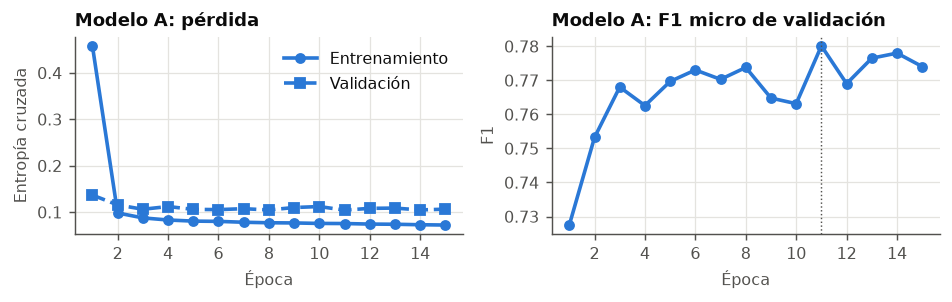

In [17]:
frozen_results = run_grid(frozen_configs)
display(grid_table(frozen_results))
best_frozen = select_best(frozen_results)
print("Configuración seleccionada:", best_frozen["config"]["name"])
print("Parámetros:", best_frozen["parameters"])
print(f"Tiempo de entrenamiento: {best_frozen['train_seconds'] / 60:.2f} min "
      f"(incluida validación: {best_frozen['total_seconds'] / 60:.2f} min)")
display(pd.DataFrame(best_frozen["history"]).round(4))
plot_run(best_frozen, "A", "Modelo A")

**Lectura del modelo A.** La mejor configuración (LR 3e-3, lote 16) alcanza un F1 de validación de 0.7801 en la época 11, con 6 921 parámetros entrenables y 5.87 min de entrenamiento. Las seis configuraciones quedan entre 0.7728 y 0.7801, de modo que los hiperparámetros apenas importan. Desde la época 3 la pérdida de validación se mantiene cerca de 0.106 y la de entrenamiento solo baja de 0.088 a 0.072. No hay sobreajuste: el techo lo impone la capacidad de una capa lineal sobre representaciones fijas.

### 3.5 Modelo B: *fine-tuning* completo

Se entrena conjuntamente BETO y la cabeza, partiendo de los mismos pesos y datos tokenizados que el modelo A.

[full_lr2e-05_bs16] recuperada de disco: F1 val 0.8677


[full_lr2e-05_bs32] recuperada de disco: F1 val 0.8700


[full_lr3e-05_bs16] recuperada de disco: F1 val 0.8633


[full_lr3e-05_bs32] recuperada de disco: F1 val 0.8771


[full_lr5e-05_bs16] recuperada de disco: F1 val 0.8681


[full_lr5e-05_bs32] recuperada de disco: F1 val 0.8743


,Corrida,LR,Batch,Épocas,Mejor época,F1 val,Entrenamiento (min)
0,full_lr3e-05_bs32,0.00003,32,6,3,0.8771,8.86
1,full_lr5e-05_bs32,0.00005,32,7,4,0.8743,10.22
2,full_lr2e-05_bs32,0.00002,32,8,5,0.8700,12.10
3,full_lr5e-05_bs16,0.00005,16,7,4,0.8681,10.17
4,full_lr2e-05_bs16,0.00002,16,8,5,0.8677,11.85
5,full_lr3e-05_bs16,0.00003,16,7,4,0.8633,10.16


Configuración seleccionada: full_lr3e-05_bs32
Parámetros: {'entrenables': 109267209, 'totales': 109267209}
Tiempo de entrenamiento: 8.86 min (incluida validación: 9.45 min)


,epoch,train_loss,val_loss,val_f1,train_seconds
0,1,0.3986,0.0907,0.8102,89.1196
1,2,0.0462,0.0856,0.8372,88.5425
2,3,0.0265,0.0776,0.8771,88.3454
3,4,0.0168,0.0849,0.8709,89.4615
4,5,0.0115,0.0947,0.8705,88.5872
5,6,0.0082,0.1025,0.8579,87.5191


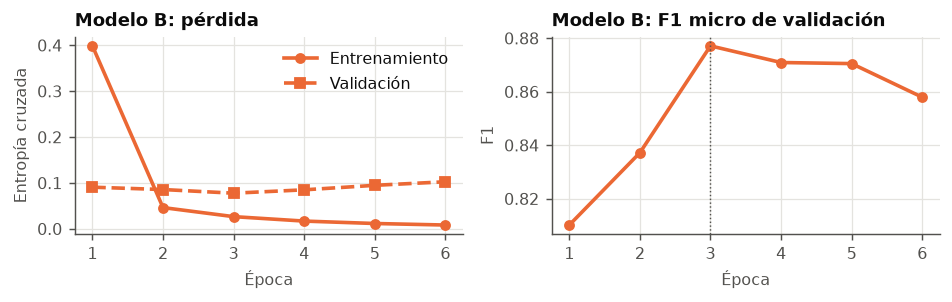

In [18]:
full_results = run_grid(full_configs)
display(grid_table(full_results))
best_full = select_best(full_results)
print("Configuración seleccionada:", best_full["config"]["name"])
print("Parámetros:", best_full["parameters"])
print(f"Tiempo de entrenamiento: {best_full['train_seconds'] / 60:.2f} min "
      f"(incluida validación: {best_full['total_seconds'] / 60:.2f} min)")
display(pd.DataFrame(best_full["history"]).round(4))
plot_run(best_full, "B", "Modelo B")

**Lectura del modelo B.** Las seis configuraciones superan a cualquier modelo congelado, con F1 de validación entre 0.8633 y 0.8771. La seleccionada (LR 3e-5, lote 32) alcanza 0.8771 en la época 3, con 109 267 209 parámetros entrenables y 8.86 min de entrenamiento.

La pérdida de validación toca su mínimo de 0.0776 en la época 3 y sube hasta 0.1025 en la época 6, mientras la de entrenamiento baja de 0.0265 a 0.0082. Es sobreajuste claro, y por eso se conserva el estado de la época 3 y la parada temprana corta la corrida. Con los tres LR el lote 32 supera al lote 16. El F1 varía alrededor de 0.01 entre épocas vecinas, así que una diferencia de 0.003 entre las dos mejores configuraciones no es concluyente.

,Corrida,F1 val registrado,F1 val recuperado
0,frozen_lr3e-03_bs16,0.7801,0.7801
1,full_lr3e-05_bs32,0.8771,0.8771


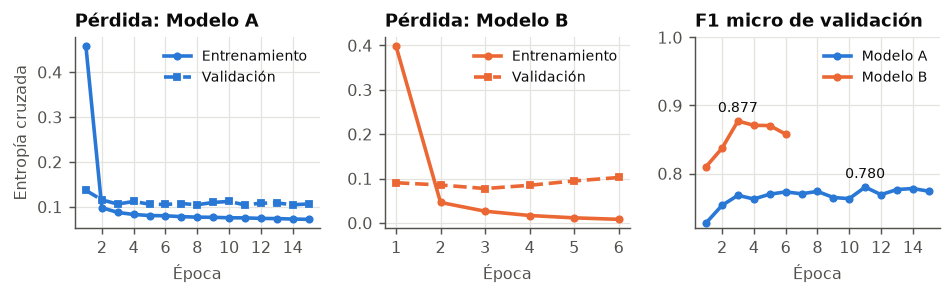

In [19]:
# Recuperación de los checkpoints seleccionados, verificada frente a su F1 de validación.
restored = pd.DataFrame([verify_restored(best_frozen), verify_restored(best_full)])
assert {r["fingerprint"] for r in frozen_results + full_results} == {fingerprints["train"]}, "datos distintos"
display(restored)

fig, (ax_a, ax_b, ax_f1) = plt.subplots(1, 3, figsize=(7.4, 2.35))
for ax, result, key, label in ((ax_a, best_frozen, "A", "Modelo A"), (ax_b, best_full, "B", "Modelo B")):
    history = pd.DataFrame(result["history"])
    ax.plot(history["epoch"], history["train_loss"], "o-", color=MODEL_COLORS[key], label="Entrenamiento", markersize=3.5)
    ax.plot(history["epoch"], history["val_loss"], "s--", color=MODEL_COLORS[key], label="Validación", markersize=3.5)
    ax.set(title=f"Pérdida: {label}", xlabel="Época")
    ax.legend(fontsize=7.5)
    ax_f1.plot(history["epoch"], history["val_f1"], "o-", color=MODEL_COLORS[key], label=label, markersize=3.5)
    ax_f1.annotate(f"{result['best_val_f1']:.3f}", (result["best_epoch"], result["best_val_f1"]),
                   textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8, color=INK)
ax_a.set_ylabel("Entropía cruzada")
ax_f1.set(title="F1 micro de validación", xlabel="Época")
ax_f1.set_ylim(top=1)
ax_f1.legend(fontsize=7.5, loc="upper right")
for ax in (ax_a, ax_b, ax_f1):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
save_figure(fig, "curvas")

## 4. Evaluación final

A partir de aquí no se toma ninguna decisión sobre los modelos. `evaluate_on_test_once` evalúa los dos checkpoints seleccionados y guarda métricas y predicciones; si el archivo ya existe, lo lee en lugar de volver a evaluar. Todo el análisis posterior parte de esas predicciones guardadas.

In [20]:
def evaluate_on_test_once(selected: dict) -> dict:
    """Evalúa una sola vez cada modelo seleccionado; las ejecuciones siguientes leen el resultado."""
    path = OUT_DIR / "test_results.json"
    if path.exists():
        log("Resultados de prueba recuperados de disco: la prueba no se vuelve a evaluar.")
        return json.loads(path.read_text())
    final_split = "validación" if SMOKE else "prueba"
    results = {}
    for key, result in selected.items():
        model = load_best(result)
        evaluation = evaluate(model, encoded_splits[final_split], splits[final_split])
        results[key] = {name: value for name, value in evaluation.items() if name != "loss"}
        results[key]["config"] = result["config"]["name"]
        del model
        free_memory()
    results["gold"] = splits[final_split].tags
    path.write_text(json.dumps(results, default=float))
    log(f"Evaluación final realizada sobre '{final_split}'.")
    return results


test_results = evaluate_on_test_once({"A": best_frozen, "B": best_full})
gold_tags = test_results["gold"]
assert all(abs(independent_micro_f1(gold_tags, test_results[k]["predicted"]) - test_results[k]["micro_f1"]) < 1e-9
           for k in ("A", "B")), "seqeval no coincide con el cálculo independiente"


def metrics_table(key: str) -> pd.DataFrame:
    """Precision, recall, F1 y soporte: micro, macro y por tipo de entidad."""
    report = test_results[key]["report"]
    rows = {"Micro global": report["micro avg"], "Macro entre tipos": report["macro avg"]}
    rows.update({kind: report[kind] for kind in ENTITY_TYPES})
    table = pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]]
    table.columns = ["Precision", "Recall", "F1", "Soporte"]
    return table.astype({"Soporte": int}).round(4)


MODEL_NAMES = {"A": "Modelo A (encoder congelado)", "B": "Modelo B (fine-tuning completo)"}
for key in ("A", "B"):
    print(f"{MODEL_NAMES[key]}: {test_results[key]['config']}")
    display(metrics_table(key))
    print(f"Exactitud por token: {test_results[key]['token_accuracy']:.4f} sobre {test_results[key]['n_tokens']} palabras sin posiciones ignoradas\n")

n_gold_words = sum(map(len, gold_tags))
baseline_accuracy = sum(tag == "O" for tags in gold_tags for tag in tags) / n_gold_words
print(f"Referencia, predecir siempre O: exactitud {baseline_accuracy:.4f}")

Resultados de prueba recuperados de disco: la prueba no se vuelve a evaluar.


Modelo A (encoder congelado): frozen_lr3e-03_bs16


,Precision,Recall,F1,Soporte
Micro global,0.7931,0.7960,0.7946,3559
Macro entre tipos,0.7570,0.7555,0.7556,3559
PER,0.9195,0.9483,0.9337,735
ORG,0.7589,0.8093,0.7833,1400
LOC,0.8451,0.7703,0.8060,1084
MISC,0.5045,0.4941,0.4993,340


Exactitud por token: 0.9759 sobre 51533 palabras sin posiciones ignoradas

Modelo B (fine-tuning completo): full_lr3e-05_bs32


,Precision,Recall,F1,Soporte
Micro global,0.8624,0.8733,0.8678,3559
Macro entre tipos,0.8331,0.8543,0.8426,3559
PER,0.9637,0.9755,0.9696,735
ORG,0.8545,0.8807,0.8674,1400
LOC,0.8917,0.8432,0.8668,1084
MISC,0.6224,0.7176,0.6667,340


Exactitud por token: 0.9851 sobre 51533 palabras sin posiciones ignoradas

Referencia, predecir siempre O: exactitud 0.8801


In [21]:
full_f1 = test_results["B"]["micro_f1"]
print(f"Requisito: F1 micro de prueba del modelo B >= 0.80 -> {full_f1:.4f}: {'CUMPLIDO' if full_f1 >= 0.80 else 'NO CUMPLIDO'}")

selected_runs = {"A": best_frozen, "B": best_full}
comparison = pd.DataFrame({
    MODEL_NAMES[key]: {
        "Configuración": run["config"]["name"],
        "F1 validación": round(run["best_val_f1"], 4),
        "F1 prueba": round(test_results[key]["micro_f1"], 4),
        "F1 macro prueba": round(test_results[key]["report"]["macro avg"]["f1-score"], 4),
        "Exactitud por token": round(test_results[key]["token_accuracy"], 4),
        "Parámetros entrenables": run["parameters"]["entrenables"],
        "Épocas ejecutadas": len(run["history"]),
        "Mejor época": run["best_epoch"],
        "Tiempo de entrenamiento (min)": round(run["train_seconds"] / 60, 2),
        "Tiempo por época (s)": round(run["train_seconds"] / len(run["history"]), 1),
        "Tiempo hasta la mejor época (min)": round(sum(h["train_seconds"] for h in run["history"][:run["best_epoch"]]) / 60, 2),
    } for key, run in selected_runs.items()
})
display(comparison)

search_cost = {key: sum(r["train_seconds"] for r in results) / 60
               for key, results in (("A", frozen_results), ("B", full_results))}
print({f"Búsqueda completa {key} (min)": round(value, 1) for key, value in search_cost.items()})
print("Razón de parámetros entrenables B/A:", round(best_full["parameters"]["entrenables"] / best_frozen["parameters"]["entrenables"]))
print("Razón de tiempo por época B/A:", round(float(comparison.loc["Tiempo por época (s)"].iloc[1] / comparison.loc["Tiempo por época (s)"].iloc[0]), 2))

Requisito: F1 micro de prueba del modelo B >= 0.80 -> 0.8678: CUMPLIDO


,Modelo A (encoder congelado),Modelo B (fine-tuning completo)
Configuración,frozen_lr3e-03_bs16,full_lr3e-05_bs32
F1 validación,0.7801,0.8771
F1 prueba,0.7946,0.8678
F1 macro prueba,0.7556,0.8426
Exactitud por token,0.9759,0.9851
Parámetros entrenables,6921,109267209
Épocas ejecutadas,15,6
Mejor época,11,3
Tiempo de entrenamiento (min),5.87,8.86
Tiempo por época (s),23.5,88.6


{'Búsqueda completa A (min)': 35.4, 'Búsqueda completa B (min)': 63.4}
Razón de parámetros entrenables B/A: 15788
Razón de tiempo por época B/A: 3.77


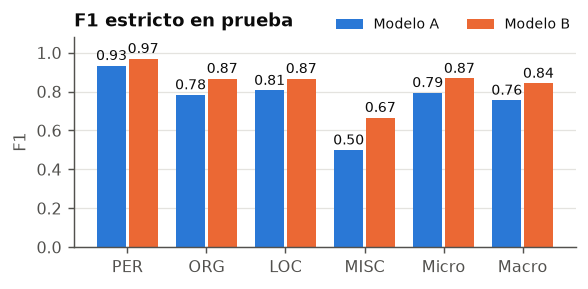

In [22]:
def bar_values(ax, bars) -> None:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012, f"{bar.get_height():.2f}",
                ha="center", va="bottom", fontsize=7.5, color=INK)


fig, ax = plt.subplots(figsize=(4.6, 2.3))
positions = np.arange(len(ENTITY_TYPES) + 2)
names = ENTITY_TYPES + ["Micro", "Macro"]
for offset, key in zip((-1, 1), ("A", "B")):
    report = test_results[key]["report"]
    values = [report[k]["f1-score"] for k in ENTITY_TYPES] + [report["micro avg"]["f1-score"], report["macro avg"]["f1-score"]]
    bars = ax.bar(positions + offset * 0.2, values, 0.37, color=MODEL_COLORS[key], label=f"Modelo {key}")
    bar_values(ax, bars)
ax.set_xticks(positions, names)
ax.set(title="F1 estricto en prueba", ylabel="F1", ylim=(0, 1.08))
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2, fontsize=7.5, borderaxespad=0)
fig.tight_layout()
save_figure(fig, "f1_por_entidad")

**Comparación de desempeño.** El modelo B gana en todas las métricas de prueba y cumple el requisito: F1 micro 0.8678 frente a 0.7946 (+0.0732) y F1 macro 0.8426 frente a 0.7556 (+0.0870). La mayor ganancia está en `MISC` (+0.1674), seguida de `ORG` (+0.0841), `LOC` (+0.0608) y `PER` (+0.0359), que ya era alto. Por eso el macro mejora más que el micro. La exactitud por token solo sube de 0.9759 a 0.9851 y predecir siempre `O` ya da 0.8801, lo que confirma que esa métrica oculta la diferencia real.

Entre validación y prueba, A sube de 0.7801 a 0.7946 y B baja de 0.8771 a 0.8678. Las particiones tienen distinta mezcla de tipos, y B además se eligió entre épocas con F1 ruidoso, de modo que parte de su F1 de validación puede ser optimismo de selección. La brecha es pequeña y B sigue muy por encima de 0.80.

**Comparación de costo.** B entrena 15 788 veces más parámetros y cada época tarda 3.77 veces más (88.6 s frente a 23.5 s). Como se detiene en 6 épocas frente a 15, el tiempo total solo es 1.51 veces mayor (8.86 frente a 5.87 min), y ambos llegan a su mejor época en un tiempo casi igual (4.43 y 4.31 min). La búsqueda completa costó 63.4 min en B y 35.4 min en A.

Estos tiempos tienen dos matices. A ejecuta el encoder en cada paso, por lo que cachear sus salidas lo abarataría mucho. Además, algunas épocas de la búsqueda de A tardaron hasta 45 s frente a los 23 s habituales, quizá por carga de la máquina, de modo que sus 35.4 min están probablemente sobreestimados; la corrida seleccionada se mantuvo estable entre 23 y 25 s. El checkpoint también difiere: 29 KB solo con la cabeza de A frente a 437 MB de B.

**Conclusión.** Para este problema conviene el *fine-tuning*: aporta 0.0732 de F1 micro a cambio de un 51 % más de tiempo de entrenamiento. El modelo congelado solo se justifica si el presupuesto de cómputo es muy limitado, y a costa de un `MISC` casi inservible (F1 0.4993).

### 4.1 Análisis de errores

Clasificar cada error explica de dónde viene la diferencia entre modelos. Se separan los errores de tipo (mismos límites), de límites (mismo tipo, solapados), de ambos, las entidades omitidas (sin solapamiento con ninguna predicción) y las predicciones espurias.

,Modelo A,Modelo B
Correcta,2833,3108
Tipo incorrecto,264,244
Límite incorrecto,234,139
Tipo y límite incorrectos,67,36
Omitida,161,32
Espuria,78,39
I-X inválidos emitidos,295,43


,pred PER,pred ORG,pred LOC,pred MISC,pred O
gold PER,1328,13,3,9,16
gold ORG,22,2177,123,97,85
gold LOC,17,164,1138,27,63
gold MISC,17,106,24,575,174
gold O,11,68,27,61,45188


,pred PER,pred ORG,pred LOC,pred MISC,pred O
gold PER,1352,7,2,0,8
gold ORG,9,2267,87,91,50
gold LOC,7,129,1208,16,49
gold MISC,11,35,11,780,59
gold O,7,38,11,54,45245


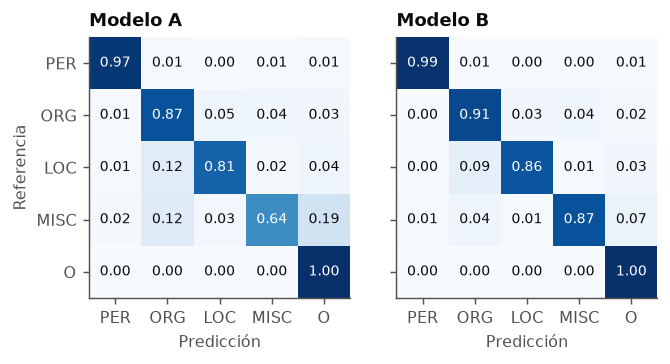

In [23]:
def classify_errors(gold: list, predicted: list) -> Counter:
    """Asigna cada entidad gold no acertada y cada predicción espuria a una categoría."""
    counts = Counter()
    for gold_tags_row, predicted_tags_row in zip(gold, predicted):
        gold_set, predicted_set = set(extract_entities(gold_tags_row)), set(extract_entities(predicted_tags_row))
        hits = gold_set & predicted_set
        counts["Correcta"] += len(hits)
        rest_gold, rest_predicted = gold_set - hits, predicted_set - hits
        for kind, start, end in rest_gold:
            overlapping = [p for p in rest_predicted if p[1] < end and start < p[2]]
            if not overlapping:
                counts["Omitida"] += 1
            elif any(p[1:] == (start, end) for p in overlapping):
                counts["Tipo incorrecto"] += 1
            elif any(p[0] == kind for p in overlapping):
                counts["Límite incorrecto"] += 1
            else:
                counts["Tipo y límite incorrectos"] += 1
        counts["Espuria"] += sum(not any(p[1] < g[2] and g[1] < p[2] for g in gold_set) for p in rest_predicted)
    return counts


def invalid_bio(predicted: list) -> int:
    """Número de I-X que el modelo emite sin una entidad abierta del mismo tipo."""
    return sum(repair_iob2(tags)[1] for tags in predicted)


error_order = ["Correcta", "Tipo incorrecto", "Límite incorrecto", "Tipo y límite incorrectos", "Omitida", "Espuria"]
error_table = pd.DataFrame({
    f"Modelo {key}": classify_errors(gold_tags, test_results[key]["predicted"]) for key in ("A", "B")
}).reindex(error_order).fillna(0).astype(int)
error_table.loc["I-X inválidos emitidos"] = [invalid_bio(test_results[key]["predicted"]) for key in ("A", "B")]
display(error_table)


def type_confusion(key: str) -> pd.DataFrame:
    """Confusión por palabra entre tipos de entidad, ignorando el prefijo BIO."""
    classes = ENTITY_TYPES + ["O"]
    flat_gold = [tag.partition("-")[2] or "O" for tags in gold_tags for tag in tags]
    flat_predicted = [tag.partition("-")[2] or "O" for tags in test_results[key]["predicted"] for tag in tags]
    matrix = confusion_matrix(flat_gold, flat_predicted, labels=classes)
    return pd.DataFrame(matrix, index=[f"gold {c}" for c in classes], columns=[f"pred {c}" for c in classes])


confusions = {key: type_confusion(key) for key in ("A", "B")}
display(confusions["A"], confusions["B"])

fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.7), sharey=True)
classes = ENTITY_TYPES + ["O"]
for ax, key in zip(axes, ("A", "B")):
    matrix = confusions[key].to_numpy()
    share = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(5), classes)
    ax.set_yticks(range(5), classes)
    ax.set(title=f"Modelo {key}", xlabel="Predicción")
    for row in range(5):
        for column in range(5):
            ax.text(column, row, f"{share[row, column]:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if share[row, column] > 0.55 else INK)
axes[0].set_ylabel("Referencia")
fig.tight_layout()
save_figure(fig, "confusion")

In [24]:
def disagreement_examples(limit: int = 6) -> pd.DataFrame:
    """Oraciones breves en las que el fine-tuning corrige al modelo congelado."""
    rows = []
    final_tokens = (splits["validación"] if SMOKE else splits["prueba"]).tokens
    for words, gold, predicted_a, predicted_b in zip(final_tokens, gold_tags, test_results["A"]["predicted"],
                                                     test_results["B"]["predicted"]):
        if gold == predicted_b and gold != predicted_a and len(words) <= 18:
            rows.append({"Referencia y modelo B": annotate(words, gold), "Modelo A": annotate(words, predicted_a)})
        if len(rows) == limit:
            break
    return pd.DataFrame(rows)


def model_b_failures(limit: int = 6) -> pd.DataFrame:
    """Oraciones breves en las que incluso el modelo B falla."""
    rows = []
    final_tokens = (splits["validación"] if SMOKE else splits["prueba"]).tokens
    for words, gold, predicted in zip(final_tokens, gold_tags, test_results["B"]["predicted"]):
        if gold != predicted and len(words) <= 16:
            rows.append({"Referencia": annotate(words, gold), "Modelo B": annotate(words, predicted)})
        if len(rows) == limit:
            break
    return pd.DataFrame(rows)


display(disagreement_examples(), model_b_failures())

,Referencia y modelo B,Modelo A
0,""" ¿ Por qué luchamos , vivimos y comimos juntos 22 años ?",""" [¿]MISC Por qué luchamos , vivimos y comimos juntos 22 años ?"
1,""" Si gana el [Real Madrid]ORG me alegraría por lo que le toca a mi hermano .",""" Si gana el [Real]ORG Madrid me alegraría por lo que le toca a mi hermano ."
2,"[EFE]ORG - [Cantabria]LOC [Madrid]LOC , 23 may ( [EFECOM]ORG ) .","[EFE]ORG - [Cantabria]LOC Madrid , 23 may ( [EFECOM]ORG ) ."
3,"El índice intermedio [FTSE 250]MISC avanzó 20,1 puntos y quedó a 6.152,0 puntos .","El índice intermedio [FTSE]MISC 250 avanzó 20,1 puntos y quedó a 6.152,0 puntos ."
4,"[BP]ORG SUBIO ENTRE 3. 1 PESETAS GASOLINAS Y MANTIENE PRECIO GASOLEO , ref .","[BP]MISC SUBIO ENTRE 3. 1 PESETAS GASOLINAS Y MANTIENE PRECIO GASOLEO , ref ."
5,"[EFECOM]ORG RS-c [Bruselas]LOC , 23 may ( [EFE]ORG ) .","[EFECOM]ORG [RS-c]ORG [Bruselas]LOC , 23 may ( [EFE]ORG ) ."


,Referencia,Modelo B
0,"EFE rc2305001855 por ciento , 23 may ( [EFE]ORG ) .","[EFE]ORG rc2305001855 por ciento , 23 may ( [EFE]ORG ) ."
1,"Porque nosotros somos aliados de [Israel]ORG , como este país lo es de [EEUU]ORG .","Porque nosotros somos aliados de [Israel]ORG , como este país lo es de [EEUU]LOC ."
2,"[EFECOM]ORG eco/ /Mc [Zaragoza]LOC , 23 may ( [EFE]ORG ) .","[EFECOM]ORG eco/ /Mc Zaragoza , 23 may ( [EFE]ORG ) ."
3,"[EFE]ORG eco/ /Mc [Zaragoza]LOC , 23 may ( [EFE]ORG ) .","[EFE]ORG eco/ /Mc Zaragoza , 23 may ( [EFE]ORG ) ."
4,[Calidad del entrenamiento de los jóvenes deportistas ']MISC .,Calidad del entrenamiento de los jóvenes deportistas ' .
5,"[Naciones Unidas]ORG , 23 may ( [EFE]ORG ) .","[Naciones]ORG Unidas , 23 may ( [EFE]ORG ) ."


**Lectura de los errores.** B acierta 3108 de las 3559 entidades, 275 más que A. El mayor avance está en las omisiones (161 → 32), los errores de límite (234 → 139), las predicciones espurias (78 → 39) y los `I-X` inválidos (295 → 43). Ajustar el encoder mejora sobre todo la detección y la delimitación, algo coherente con un encoder que aprende el contexto de este corpus.

Los errores de tipo casi no cambian (264 → 244) y son la mayoría de los 451 fallos restantes de B. Las matrices de confusión muestran que `MISC` deja de perderse como `O` (174 → 59 palabras) o como `ORG` (106 → 35), pero persiste la confusión `LOC`/`ORG` (129 y 87 palabras en B). Esta es en buena parte metonimia: en la referencia, `Israel` y `EEUU` figuran como `ORG` en una frase donde B elige `LOC` para `EEUU`. Algunos errores vienen de la propia anotación, como el primer `EFE` de `EFE rc2305001855`, que B marca y la referencia no.

In [ ]:
def round_report(report: dict) -> dict:
    return {kind: {metric: round(value, 4) for metric, value in values.items()} for kind, values in report.items()}

summary = {
    "environment": environment,
    "max_length": MAX_LENGTH,
    "corpus": corpus_summary.to_dict("index"),
    "entities": entity_counts.to_dict("index"),
    "grids": {key: grid_table(results).to_dict("records") for key, results in (("A", frozen_results), ("B", full_results))},
    "selected": {key: {field: run[field] for field in ("config", "parameters", "best_epoch", "best_val_f1", "train_seconds", "total_seconds")}
                 | {"epochs_run": len(run["history"])} for key, run in selected_runs.items()},
    "test": {key: {"micro_f1": test_results[key]["micro_f1"], "token_accuracy": test_results[key]["token_accuracy"],
                   "n_tokens": test_results[key]["n_tokens"], "report": round_report(test_results[key]["report"])}
             for key in ("A", "B")},
    "baseline_accuracy": baseline_accuracy,
    "search_minutes": search_cost,
    "errors": error_table.to_dict(),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float))

# Revisión final automática de los requisitos verificables.
checks = {
    "Modelo A: solo cabeza entrenable (6921 parámetros)": best_frozen["parameters"]["entrenables"] == len(LABELS) * 769,
    "Modelo B: todos los parámetros entrenables": best_full["parameters"]["entrenables"] == best_full["parameters"]["totales"],
    "Mismos datos tokenizados en todas las corridas": {r["fingerprint"] for r in frozen_results + full_results} == {fingerprints["train"]},
    "Misma longitud máxima en todas las corridas": {r["max_length"] for r in frozen_results + full_results} == {MAX_LENGTH},
    "Curvas con pérdida y F1 por época": all({"train_loss", "val_loss", "val_f1"} <= set(h) for r in selected_runs.values() for h in r["history"]),
    "Selección por validación": all(r["best_val_f1"] == max(h["val_f1"] for h in r["history"]) for r in selected_runs.values()),
    "Micro, macro y cuatro tipos en el informe": all({"micro avg", "macro avg", *ENTITY_TYPES} <= set(test_results[k]["report"]) for k in ("A", "B")),
    "Gold evaluado completo": sum(test_results["B"]["report"][k]["support"] for k in ENTITY_TYPES) == sum(len(extract_entities(t)) for t in gold_tags),
    "F1 micro de prueba del modelo B >= 0.80": full_f1 >= 0.80,
}
pd.Series(checks, name="Cumplido").to_frame()

,Cumplido
Modelo A: solo cabeza entrenable (6921 parámetros),True
Modelo B: todos los parámetros entrenables,True
Mismos datos tokenizados en todas las corridas,True
Misma longitud máxima en todas las corridas,True
Curvas con pérdida y F1 por época,True
Selección por validación,True
"Micro, macro y cuatro tipos en el informe",True
Gold evaluado completo,True
F1 micro de prueba del modelo B >= 0.80,True
